# 실제 Agent HTTP 통합

**이 노트북에서 할 일**

1. 실제 모델과 도구를 쓰는 실습 에이전트를 요청 주소 `/v1/chat/live`로 불러 JSON 답을 받습니다.
2. 같은 에이전트를 요청 주소 `/v1/chat/live/stream`으로 불러, 스트림 청크가 SSE 사건으로 오는 모양을 봅니다.
3. 앱이 노드 `model`의 스트림 청크만 보내는 까닭을 실험으로 확인합니다.

**준비물** — 이 노트북은 이 챕터에서 처음으로 실제 모델을 부릅니다.
프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
키가 없으면 키를 확인하는 셀에서 멈추고, 모델 요청은 나가지 않습니다.
모델은 실습 앱 파일에 적힌 `gpt-5.4-mini`입니다.

모델 요청은 에이전트가 도구를 한 번씩 부르면 여섯 번입니다.
3·4·5절에서 에이전트를 한 번씩 실행하고, 실행마다 요청이 두 번 나갑니다.
요금표(2026-09-17)로 어림한 비용은 0.002달러보다 적습니다.
청구 금액이 아니라, 교재를 만들 때 본 사용량으로 어림한 값입니다.
실행마다 답 글이 달라질 수 있습니다.

요청은 시험용 클라이언트로 같은 노트북 안에서 보냅니다.
서버 프로그램을 띄우지 않고, 포트를 쓰지 않습니다.
네트워크는 모델 서비스에 요청을 보낼 때만 씁니다.
실습 폴더의 파일은 가져오고 읽기만 하며, 쓰는 파일은 없습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 첫 셀에서 패키지 여덟을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
실습 앱 파일은 패키지 langgraph 1.2.11과 langchain 1.4.0을 가져옵니다.
모델을 부를 때는 패키지 langchain-openai 1.6.0을 씁니다.
패키지 python-dotenv 1.2.1은 `.env` 파일에서 키를 읽을 때 씁니다.

여덟 모두 실습 폴더 잠금과 같은 판입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절의 앱 파일 줄을 읽고, 5절 실험의 가설을 함께 세웁니다.
모델을 부르는 3~5절의 셀은 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 파란 상자 시험용 클라이언트 같은 질문 thread_id live-1에서 초록 상자 둘로 갈라집니다. 왼쪽은 POST /v1/chat/live ainvoke로 기다림, 오른쪽은 POST /v1/chat/live/stream astream 모드 messages입니다. 두 상자는 초록 상자 제공 함수 get_live_agent build_live_agent 같은 객체 True로 모이고, 보라 상자 에이전트 그래프 노드 model과 tools gpt-5.4-mini로 이어집니다. 맨 아래 노란 상자 둘은 JSON 응답 200 칸 answer와 thread_id, SSE 응답 200 token 사건들 뒤 done인 그림](attachment:09-1-두-요청-주소와-실제-에이전트.png)

위에서 아래로 읽습니다.
파란 상자는 노트북이 보낸 요청이고, 초록 상자는 실습 앱의 처리 함수와 제공 함수입니다.
보라 상자는 이 절에서 실제로 부른 모델을 쓰는 에이전트 그래프입니다.
노란 상자 둘은 노트북 3절과 4절의 출력입니다.
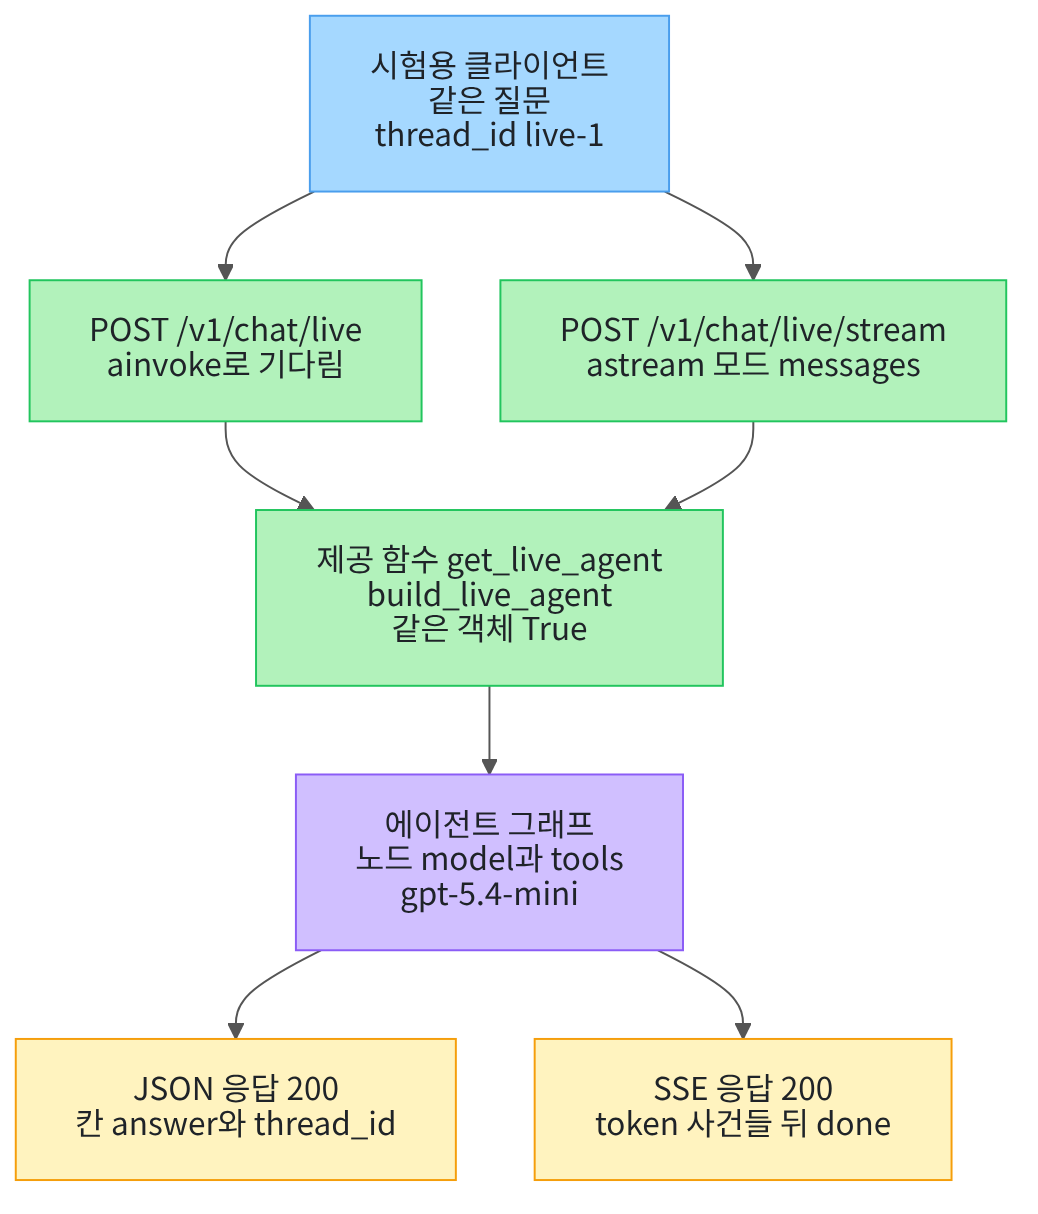

## 1. 준비

08절에서는 앱 객체가 만든 응답 문서를 읽었고, 요청 주소 다섯이 적혀 있었습니다.
01~08절의 요청 주소는 모델을 쓰지 않는 그래프를 불렀습니다.
이 절은 남은 두 요청 주소 `/v1/chat/live`와 `/v1/chat/live/stream`을 부릅니다.
두 요청 주소는 실제 모델과 도구를 쓰는 에이전트를 부릅니다.

제목의 Agent는 에이전트를 가리키고, HTTP는 웹에서 요청과 응답을 주고받는 규칙입니다.
제목의 통합은 실제 에이전트를 앱의 처리 함수에 이어, 요청 하나로 끝까지 실행하는 일입니다.
첫 셀은 패키지 여덟을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0" "langgraph==1.2.11" "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.1"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))
print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0
langgraph: 1.2.11
langchain: 1.4.0
langchain-openai: 1.6.0


python-dotenv: 1.2.1


**결과 읽기** — 출력 줄 `langchain-openai: 1.6.0`과 `python-dotenv: 1.2.1`이 보입니다.
07·08절의 패키지 여섯에 두 패키지를 더했습니다.
패키지 langchain-openai는 실습 앱이 OpenAI 모델을 부를 때 씁니다.
패키지 python-dotenv는 `.env` 파일에서 키를 읽을 때 씁니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
04·06절에서 배운 함수 다섯은 도구 파일 `serve_tools.py`에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os와 json은 Python에 들어 있는 모듈입니다)
import os
import json
from fastapi.testclient import TestClient
# 04·06절에서 배운 함수 다섯은 도구 파일에서 가져옵니다
from serve_tools import ended_with_done, event_names, join_tokens, read_events, token_values

print("가져온 이름:", "json, TestClient")
print("도구 파일에서 가져온 함수:", "ended_with_done, event_names, join_tokens, read_events, token_values")

가져온 이름: json, TestClient
도구 파일에서 가져온 함수: ended_with_done, event_names, join_tokens, read_events, token_values


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수:` 뒤에 함수 다섯이 보입니다.
함수 `join_tokens`는 04절에서, 나머지 넷은 06절에서 배웠습니다.
06절 함수 넷은 이 절부터 도구 파일에 있고, 그 절 노트북의 셀을 주석과 본문 그대로 옮겼습니다.
함수 `read_events`가 부르는 05절 함수 `split_sse`와 `parse_sse`도 도구 파일에 있습니다.
함수 `token_values`가 모듈 json을 쓰므로, 도구 파일 머리에 가져오기 줄 하나를 더했습니다.

앞에서 배운 함수는 `serve_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 `.env` 파일에서 API 키를 읽고, 키가 있는지만 출력합니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`가 보입니다.
키 값은 출력하지 않고, 있는지만 봅니다.
키가 없으면 이 셀의 `assert`가 멈추고, `.env` 파일에 키를 적으라는 글을 보입니다.
그러면 뒤 셀로 가지 않아, 모델 요청도 나가지 않습니다.

다음 셀은 01절 2절과 같은 파일 위치 셀로, 후보 셋 가운데 실습 폴더를 고릅니다.

In [4]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.
실습 폴더 맨 위에서 연 커널은 이 안내를 보기 전에, 앞 셀의 도구 파일 가져오기에서 먼저 멈춥니다.

다음 셀은 작업 폴더를 실습 폴더로 옮긴 뒤 이름을 가져옵니다.
앱 파일에서는 앱 객체 `app`을 가져옵니다.
실제 에이전트 파일 `live_agent.py`에서는 에이전트를 만드는 함수와 도구를 가져옵니다.

In [5]:
# 작업 폴더를 실습 폴더로 옮기고, 앱 객체와 실제 에이전트 파일의 두 이름을 가져옵니다
os.chdir(lab_path)
from agent_service.app import app
from agent_service.live_agent import build_live_agent, lookup_library_hours
print("가져온 앱 객체의 종류:", type(app).__name__)
print("가져온 함수:", build_live_agent.__name__)
print("가져온 도구의 종류와 이름:", type(lookup_library_hours).__name__, lookup_library_hours.name)

가져온 앱 객체의 종류: FastAPI
가져온 함수: build_live_agent
가져온 도구의 종류와 이름: StructuredTool lookup_library_hours


**결과 읽기** — 출력 줄 `가져온 도구의 종류와 이름: StructuredTool lookup_library_hours`가 보입니다.
Ch 19 01절에서 본 것처럼, 데코레이터 줄 `@tool`로 등록한 함수는 도구 객체가 됩니다.
함수 `build_live_agent`는 아직 부르지 않아서, 모델 객체도 아직 없습니다.

## 2. 실습 앱의 실제 에이전트

파일 `agent_service/live_agent.py`는 실제 모델과 도구 하나로 에이전트를 만듭니다.
Ch 21 01절에서 함수 `create_agent`로 만든 에이전트 그래프와 같은 모양입니다.
다음 셀은 이 파일을 글로 읽어, 도구 함수가 적힌 8~12행을 출력합니다.

In [6]:
# 실제 에이전트 파일을 글로 읽어, 도구 함수가 적힌 8~12행을 출력합니다
first_line = 8
last_line = 12
with open("agent_service/live_agent.py", encoding="utf-8") as agent_file:
    agent_lines = agent_file.read().splitlines()
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", agent_lines[index])

줄 번호 | 줄
8 | @tool
9 | def lookup_library_hours(day: str) -> str:
10 |     """한빛도서관의 요일별 운영 시간을 조회합니다."""
11 |     hours = {"월요일": "09:00~18:00", "화요일": "09:00~21:00"}
12 |     return hours.get(day, "해당 요일의 운영 시간 정보가 없습니다")


**결과 읽기** — 라벨 줄 아래 8~12행이 도구 함수 `lookup_library_hours`입니다.
11행의 딕셔너리가 요일별 운영 시간 표이고, 월요일과 화요일만 있습니다.
12행의 메서드 `get`은 표에 없는 요일이면 둘째 인자의 글을 내놓습니다.
10행의 독스트링은 모델이 도구를 고를 때 읽는 설명입니다.

다음 셀은 이 도구를 모델 없이 직접 불러, 표에 있는 요일과 없는 요일의 결과를 봅니다.
Ch 19 05절처럼, 도구의 메서드 `invoke`에 인자 딕셔너리를 넣습니다.

In [7]:
# 도구를 모델 없이 직접 불러, 표에 있는 요일과 없는 요일의 결과를 봅니다(모델 요청 0)
monday_result = lookup_library_hours.invoke({"day": "월요일"})
sunday_result = lookup_library_hours.invoke({"day": "일요일"})
print("월요일:", monday_result)
print("일요일:", sunday_result)

월요일: 09:00~18:00
일요일: 해당 요일의 운영 시간 정보가 없습니다


**결과 읽기** — 출력 줄 `월요일: 09:00~18:00`이 보입니다.
표에 없는 일요일은 「해당 요일의 운영 시간 정보가 없습니다」라는 글을 받았습니다.
도구는 우리가 적은 평범한 함수라, 같은 인자에는 늘 같은 글을 내놓습니다.
월요일 결과 `09:00~18:00`은 5절 실험에서 다시 씁니다.

다음 셀은 같은 파일에서 모델 객체와 에이전트를 만드는 15~28행을 출력합니다.

In [8]:
# 같은 파일에서 모델 객체와 에이전트를 만드는 15~28행을 출력합니다
first_line = 15
last_line = 28
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", agent_lines[index])

줄 번호 | 줄
15 | @lru_cache(maxsize=1)
16 | def build_live_agent():
17 |     """환경 변수의 OpenAI 키를 사용하는 실제 도구 호출 Agent를 만듭니다."""
18 |     model = init_chat_model(
19 |         "openai:gpt-5.4-mini",
20 |         temperature=0,
21 |         reasoning_effort="none",
22 |         timeout=30,
23 |     )
24 |     return create_agent(
25 |         model=model,
26 |         tools=[lookup_library_hours],
27 |         system_prompt="도서관 운영 시간 질문은 반드시 도구로 확인한 뒤 한국어 한 문장으로 답하세요.",
28 |     )


**결과 읽기** — 라벨 줄 아래 18~23행이 모델 객체를 만드는 줄입니다.
20행 `temperature=0`과 21행 `reasoning_effort="none"`은 이 과정의 모델 셀과 같은 설정입니다.
22행 `timeout=30`은 Ch 6 05절의 인자로, 모델 요청 하나를 30초까지 기다린다는 뜻입니다.
24~28행은 Ch 21 01절처럼 모델과 도구, 시스템 메시지 글을 함수 `create_agent`에 넘깁니다.
이 노트북의 출력은 2026-09-29에 이 모델로 실행한 결과입니다.

15행 `@lru_cache(maxsize=1)`은 함수가 처음 만든 결과를 담아 두게 하는 데코레이터 줄입니다.
그래서 두 번째로 부르면, 에이전트를 다시 만들지 않고 담아 둔 객체를 내놓습니다.
27행의 시스템 메시지 글은 운영 시간 질문을 반드시 도구로 확인하라고 적습니다.
그래도 도구를 부를지는 모델이 정하므로, 실행마다 같다고 할 수 없습니다.

다음 셀은 에이전트를 만드는 함수를 두 번 불러, 같은 객체인지 봅니다.
모델 객체를 만들 때 키가 필요하지만, 모델 요청은 아직 나가지 않습니다.

In [9]:
# 에이전트를 만드는 함수를 두 번 불러, 같은 객체인지와 그래프의 노드 이름을 봅니다(모델 요청 0)
live_agent = build_live_agent()
again_agent = build_live_agent()
graph_view = live_agent.get_graph()
print("두 번 부른 결과가 같은 객체인가:", live_agent is again_agent)
print("그래프의 노드 이름:", list(graph_view.nodes))

두 번 부른 결과가 같은 객체인가: True
그래프의 노드 이름: ['__start__', 'model', 'tools', '__end__']


**결과 읽기** — 출력 줄 `두 번 부른 결과가 같은 객체인가: True`가 보입니다.
앱의 제공 함수 `get_live_agent`도 이 함수를 불러 에이전트를 넘깁니다.
그래서 3·4절의 요청은 이 셀의 `live_agent`와 같은 객체를 씁니다.
그래프의 노드 `model`은 모델을 부르고, 노드 `tools`는 모델이 요청한 도구를 실행합니다.
Ch 21 01절에서 본 것처럼, 모델이 도구를 더 요청하지 않으면 실행이 끝납니다.

## 3. 요청 주소 /v1/chat/live

요청 주소 `/v1/chat/live`는 03절의 `/v1/chat`처럼 JSON 글로 답합니다.
다른 점은 제공 함수가 넘기는 에이전트가 실제 모델을 부른다는 것입니다.
다음 셀은 앱 파일에서 이 요청 주소의 처리 함수 86~92행을 출력합니다.

In [10]:
# 앱 파일을 글로 읽어, 요청 주소 /v1/chat/live의 처리 함수 86~92행을 출력합니다
first_line = 86
last_line = 92
with open("agent_service/app.py", encoding="utf-8") as app_file:
    app_lines = app_file.read().splitlines()
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", app_lines[index])

줄 번호 | 줄
86 | @app.post("/v1/chat/live", response_model=ChatResponse)
87 | async def live_chat(body: ChatRequest, runtime: LiveAgentDep, _token: AuthDep) -> ChatResponse:
88 |     result = await asyncio.wait_for(
89 |         runtime.ainvoke({"messages": [{"role": "user", "content": body.question}]}),
90 |         timeout=45.0,
91 |     )
92 |     return ChatResponse(answer=result["messages"][-1].text, thread_id=body.thread_id)


**결과 읽기** — 라벨 줄 아래 87행에서 매개변수 `runtime`의 힌트가 `LiveAgentDep`입니다.
02절에서 본 의존성이라, 제공 함수 `get_live_agent`가 만든 에이전트가 들어옵니다.
88~91행은 03절처럼 `ainvoke`를 await로 기다리고, 45초 시간 제한을 겁니다.
92행은 결과 딕셔너리의 칸 `messages`에서 마지막 메시지의 글을 답으로 꺼냅니다.

02절의 `/v1/chat`은 시간 제한을 넘기면 상태 코드 504로 답했습니다.
이 처리 함수에는 그렇게 바꾸는 줄이 없어, 시간 제한 오류가 그대로 올라갑니다.
이 노트북에서는 시간 제한을 넘기는 장면을 실행하지 않았습니다.

다음 셀은 시험용 클라이언트로 이 요청 주소에 질문을 보냅니다.
요청 머리와 요청 본문은 02절부터 써 온 모양이고, 질문만 도서관 운영 시간으로 바꿨습니다.
에이전트가 도구를 한 번 부르면, 이 셀에서 모델 요청이 두 번 나갑니다.

In [11]:
# 시험용 클라이언트로 요청 주소 /v1/chat/live에 질문을 보냅니다(도구를 한 번 부르면 모델 요청 2번)
client = TestClient(app)
auth_headers = {"Authorization": "Bearer local-demo-token"}
question_body = {"question": "한빛도서관 월요일 운영 시간은?", "thread_id": "live-1"}
live_response = client.post("/v1/chat/live", json=question_body, headers=auth_headers)
live_body = live_response.json()
print("상태 코드:", live_response.status_code)
print("응답 본문의 칸:", list(live_body))
print("thread_id:", live_body["thread_id"])
print("답 글:", live_body["answer"])

상태 코드: 200
응답 본문의 칸: ['answer', 'thread_id']
thread_id: live-1
답 글: 한빛도서관 월요일 운영 시간은 09:00~18:00입니다.


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `응답 본문의 칸: ['answer', 'thread_id']`가 보입니다.
칸 `thread_id`는 보낸 그대로 `live-1`입니다.
응답 본문의 칸은 01절의 응답 형식 `ChatResponse`가 정한 둘뿐입니다.
그래서 에이전트가 도구를 불렀는지, 모델 요청이 몇 번 나갔는지는 이 응답에 나오지 않습니다.

라벨 `답 글:` 뒤의 글은 모델이 쓴 글이라, 실행마다 달라질 수 있습니다.
교재 출력에서는 도구가 내놓는 시각 `09:00~18:00`이 답 글에 들어 있었습니다.

## 4. 요청 주소 /v1/chat/live/stream

요청 주소 `/v1/chat/live/stream`은 05절의 `/v1/chat/stream`처럼 SSE 사건으로 답합니다.
다음 셀은 이 요청 주소의 처리 함수 127~154행을 출력합니다.

In [12]:
# 앱 파일에서 요청 주소 /v1/chat/live/stream의 처리 함수 127~154행을 출력합니다
first_line = 127
last_line = 154
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", app_lines[index])

줄 번호 | 줄
127 | @app.post("/v1/chat/live/stream", response_class=EventSourceResponse)
128 | async def live_chat_stream(
129 |     body: ChatRequest, runtime: LiveAgentDep, _token: AuthDep
130 | ) -> AsyncIterable[ServerSentEvent]:
131 |     index = 0
132 |     try:
133 |         async with asyncio.timeout(45.0):
134 |             async for message, metadata in runtime.astream(
135 |                 {"messages": [{"role": "user", "content": body.question}]},
136 |                 stream_mode="messages",
137 |             ):
138 |                 if metadata.get("langgraph_node") != "model":
139 |                     continue
140 |                 for block in message.content_blocks:
141 |                     if block.get("type") == "text" and block.get("text"):
142 |                         yield ServerSentEvent(
143 |                             data={"token": block["text"]},
144 |                             event="token",
145 |                             id=_event_id(body.thread_id, 

**결과 읽기** — 라벨 줄 아래 134~137행이 04절의 메서드 `astream`을 모드 `messages`로 부릅니다.
Ch 25 02절에서 본 것처럼, 이 모드의 스트림 사건은 스트림 청크와 칸 `metadata`의 짝입니다.
134행은 for 줄에 이름 둘을 적어, 짝의 앞 값을 `message`에, 뒤 값을 `metadata`에 받습니다.
138~139행은 칸 `metadata`의 노드 이름이 `model`이 아니면, `continue`로 다음 사건에 넘어갑니다.
140~147행은 글 블록 가운데 글이 있는 것만 골라, 사건 번호를 붙인 token 사건으로 보냅니다.

133행은 05절에서 본 `asyncio.timeout`으로 45초 시간 제한을 겁니다.
148행은 끝에 `done` 사건을 보내고, 149~154행은 오류가 나면 오류 사건을 보냅니다.
오류 코드는 06절의 `stream_failed`와 다른 `live_stream_failed`입니다.
이 노트북에서는 오류 사건이 나오는 장면을 실행하지 않았습니다.

다음 셀은 같은 질문을 이 요청 주소로 보내고, 응답 본문을 SSE 사건으로 읽습니다.
06절 함수 `read_events`는 본문 글을 사건마다 칸 딕셔너리로 바꿉니다.
이 셀에서도 에이전트가 도구를 한 번 부르면 모델 요청이 두 번 나갑니다.

In [13]:
# 같은 질문을 요청 주소 /v1/chat/live/stream에 보내고, 응답 본문을 SSE 사건으로 읽습니다(도구를 한 번 부르면 모델 요청 2번)
stream_response = client.post("/v1/chat/live/stream", json=question_body, headers=auth_headers)
live_events = read_events(stream_response.text)
live_names = event_names(live_events)
print("상태 코드:", stream_response.status_code)
print("본문 종류:", stream_response.headers["content-type"])
print("첫 사건과 마지막 사건의 이름:", live_names[0], live_names[-1])
print("마지막 사건이 done인가:", ended_with_done(live_events))
print("SSE 사건 수:", len(live_events))

상태 코드: 200
본문 종류: text/event-stream; charset=utf-8
첫 사건과 마지막 사건의 이름: token done
마지막 사건이 done인가: True
SSE 사건 수: 21


**결과 읽기** — 출력 줄 `본문 종류: text/event-stream; charset=utf-8`이 보입니다.
첫 사건은 `token`, 마지막 사건은 `done`입니다.
06절 함수 `ended_with_done`도 `True`라, 끝까지 받은 응답입니다.
시험용 클라이언트는 응답이 다 끝난 뒤 본문을 한꺼번에 주므로, 사건이 도착한 때는 이 출력으로 알 수 없습니다.

SSE 사건 수는 모델 서비스가 글을 몇 개로 나눠 보냈는지에 따라 달라집니다.
라벨 `SSE 사건 수:` 뒤의 값은 이번 실행의 수이고, 다시 실행하면 다를 수 있습니다.

다음 셀은 첫 사건과 끝 사건의 칸을 보고, token이 아닌 사건 이름을 모읍니다.

In [14]:
# 첫 사건의 칸 이름과 사건 번호, done 사건의 칸 data를 보고, token이 아닌 사건 이름을 모읍니다
print("첫 사건의 칸 이름:", list(live_events[0]))
print("첫 사건 번호:", live_events[0]["id"])
print("done 사건의 칸 data:", json.loads(live_events[-1]["data"]))
other_names = []
for name in live_names:
    if name != "token":
        other_names.append(name)
print("token이 아닌 사건 이름:", other_names)

첫 사건의 칸 이름: ['event', 'data', 'id']
첫 사건 번호: live-1:0
done 사건의 칸 data: {'thread_id': 'live-1'}
token이 아닌 사건 이름: ['done']


**결과 읽기** — 출력 줄 `첫 사건 번호: live-1:0`이 보입니다.
사건 번호는 05절처럼 스레드 이름과 쌍점, 0부터 센 자리입니다.
끝 사건의 칸 `data`는 `{'thread_id': 'live-1'}`이고, 칸 `id`는 없습니다.
사건 이름 가운데 token이 아닌 것은 `['done']` 하나라, 이 응답에는 오류 사건이 없었습니다.

다음 셀은 token 사건의 칸 `data`를 읽어 칸 `token`의 글을 이어 붙입니다.
이어 붙인 글을 3절의 JSON 답과 견줍니다.

In [15]:
# token 사건의 칸 data를 읽어 칸 token의 글을 이어 붙이고, 3절의 JSON 답과 견줍니다
live_values = token_values(live_events)
stream_text = join_tokens(live_values)
print("token 사건 수:", len(live_values))
print("이어 붙인 글:", stream_text)
print("3절 JSON 답과 같은가:", stream_text == live_body["answer"])

token 사건 수: 20
이어 붙인 글: 한빛도서관 월요일 운영 시간은 09:00~18:00입니다.
3절 JSON 답과 같은가: True


**결과 읽기** — 라벨 `token 사건 수:`와 `이어 붙인 글:` 뒤의 값은 모델이 쓴 글에서 나온 값이라, 실행마다 달라질 수 있습니다.
04·05절의 token 사건은 노드 코드가 낱말마다 나눈 진행 값이었습니다.
이 절의 token 사건은 모델 서비스가 나눠 보낸 스트림 청크의 글입니다.

교재 출력에서는 이어 붙인 글이 3절의 JSON 답과 같았습니다.
두 요청은 따로 실행한 것이라, 늘 같은 글이 온다고 할 수 없습니다.

## 5. 실험: 모드 messages가 내놓는 사건과 앱 138행

Ch 25 02절의 그래프는 모델을 부르는 노드가 하나뿐이었고, 스트림 청크도 그 노드에서만 왔습니다.
실습 에이전트의 그래프에는 노드 `model`과 `tools`가 있습니다.
앱 138행은 노드 이름이 `model`인 사건만 SSE 사건으로 보냅니다.
이 줄이 무엇을 거르는지 보려면, 노드 이름 조건 하나만 바꿔 견줘야 합니다.

**가설** — 모드 `messages`는 노드 `tools`가 내놓은 도구 메시지도 사건으로 내놓을 것입니다.
그렇다면 노드 `tools`의 사건까지 남기면, 도구 결과 글이 답 글 앞에 붙을 것입니다.
노드 `model`의 사건만 남기면, 앱이 보낸 글과 같은 모양이 될 것입니다.

다음 셀은 실습 에이전트를 앱 134~137행과 같은 모양으로 불러, 스트림 사건을 모두 모읍니다.
3·4절의 요청과 따로 한 번 더 실행하는 것이라, 앞 실행과 같은 차례라고 할 수 없습니다.
04절처럼 셀 맨 위에서 `async for`로 사건을 하나씩 꺼내 목록에 담습니다.
에이전트가 도구를 한 번 부르면, 이 셀에서 모델 요청이 두 번 나갑니다.

In [16]:
# 실습 에이전트를 앱 134~137행과 같은 모양으로 불러, 모드 messages의 스트림 사건을 모두 모읍니다(도구를 한 번 부르면 모델 요청 2번)
live_input = {"messages": [{"role": "user", "content": question_body["question"]}]}
message_events = []
async for event in live_agent.astream(live_input, stream_mode="messages"):
    message_events.append(event)
print("사건 하나의 종류와 길이:", type(message_events[0]).__name__, len(message_events[0]))
print("앞 값의 종류:", type(message_events[0][0]).__name__)
print("뒤 값의 종류:", type(message_events[0][1]).__name__)
print("받은 스트림 사건 수:", len(message_events))

사건 하나의 종류와 길이: tuple 2
앞 값의 종류: AIMessageChunk
뒤 값의 종류: dict
받은 스트림 사건 수: 35


**결과 읽기** — 출력 줄 `사건 하나의 종류와 길이: tuple 2`가 보입니다.
앞 값은 스트림 청크 `AIMessageChunk`이고, 뒤 값은 칸 `metadata`의 딕셔너리입니다.
Ch 25 02절과 같은 모양이라, 사건 하나를 앞 값과 뒤 값으로 나눠 읽습니다.

받은 스트림 사건 수는 모델 서비스가 글을 몇 개로 나눠 보냈는지에 따라 달라집니다.
라벨 `받은 스트림 사건 수:` 뒤의 값은 이번 실행의 수입니다.

다음 셀은 이 절에서 쓸 함수를 정의합니다.
Ch 25 02절의 함수 `mode_order`처럼, 같은 이름이 이어지면 한 번만 적어 노드가 바뀐 차례를 만듭니다.
노드 이름은 칸 `metadata`의 키 `langgraph_node`에 있습니다.

In [17]:
# 스트림 사건 목록에서 같은 노드가 이어지면 한 번만 적어, 노드가 바뀐 차례를 목록으로 내놓습니다
def node_order(message_events):
    order = []
    last_node = ""
    for event in message_events:
        # 사건 하나는 (메시지, 칸 metadata) 짝이라, [1]의 키 langgraph_node가 노드 이름입니다
        node = event[1]["langgraph_node"]
        if node != last_node:
            order.append(node)
        last_node = node
    return order

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `mode_order`는 사건 짝의 앞 값에서 모드 이름을 읽었습니다.
이 함수는 짝의 뒤 값 `event[1]`에서 노드 이름을 읽는 점만 다릅니다.

다음 셀은 노드가 바뀐 차례를 보고, 노드 `tools`에서 온 사건의 메시지를 출력합니다.

In [18]:
# 노드가 바뀐 차례를 보고, 노드 tools에서 온 사건의 메시지 종류·이름·글을 출력합니다
print("노드 차례:", node_order(message_events))
for event in message_events:
    if event[1]["langgraph_node"] == "tools":
        print("노드 tools의 사건:", type(event[0]).__name__, event[0].name, event[0].text)

노드 차례: ['model', 'tools', 'model']
노드 tools의 사건: ToolMessage lookup_library_hours 09:00~18:00


**결과 읽기** — 출력 줄 `노드 차례: ['model', 'tools', 'model']`이 보입니다.
노드 `tools`에서 온 사건은 도구 메시지 `ToolMessage` 하나이고, 글은 `09:00~18:00`입니다.
2절에서 도구를 직접 불러 받은 월요일 결과와 같은 글입니다.
가설대로 모드 `messages`는 모델의 스트림 청크뿐 아니라, 노드가 내놓은 도구 메시지도 사건으로 내놓았습니다.

노드 차례는 모델이 도구를 한 번 부르고 답을 쓴 실행의 차례입니다.
교재를 만들 때 노트북 밖에서 같은 실행을 다섯 번 해 보니, 다섯 번 모두 이 차례였습니다.
모델이 도구를 부르지 않거나 두 번 부르면 차례가 달라집니다.

다음 셀은 이 실행에서 모델 요청이 몇 번 나갔는지 셉니다.
Ch 25 02절에서는 모델 응답 하나의 스트림 청크 가운데 하나에만 사용량이 들어 있었습니다.
그래서 사용량이 든 스트림 청크 수를 모델 요청 수로 봅니다.
Ch 29 04절의 셈인 「요청 수 = 도구를 요청한 응답 수 + 1」과도 견줍니다.

In [19]:
# 사용량이 든 노드 model의 스트림 청크와 노드 tools의 사건을 세어, 이 실행의 모델 요청 수를 봅니다
usage_count = 0
tool_count = 0
for event in message_events:
    if event[1]["langgraph_node"] == "tools":
        tool_count = tool_count + 1
    if event[1]["langgraph_node"] == "model" and event[0].usage_metadata is not None:
        usage_count = usage_count + 1
print("사용량이 든 스트림 청크 수:", usage_count)
print("노드 tools의 사건 수 + 1:", tool_count + 1)

사용량이 든 스트림 청크 수: 2
노드 tools의 사건 수 + 1: 2


**결과 읽기** — 두 줄 모두 `2`입니다.
노드 `tools`의 사건이 하나이므로, 이 실행에서 도구를 요청한 응답도 하나입니다.
그래서 Ch 29 04절의 셈으로도 요청 수는 1 + 1 = 2입니다.
3·4절의 요청도 같은 에이전트라, 도구를 한 번 불렀다면 요청이 두 번씩 나갔습니다.
다만 3·4절의 응답에는 사용량이 없어, 그 요청 수는 이 노트북에서 세지 못했습니다.

노드 `tools`의 사건 수로 센 것은, 도구 메시지 하나가 도구를 요청한 응답 하나에서 나왔기 때문입니다.
한 응답이 도구를 여럿 요청하면 도구 메시지 수가 더 커져, 이 셈이 맞지 않습니다.

다음 셀은 이 절에서 쓸 함수를 하나 더 정의합니다.
스트림 사건 가운데 노드 이름이 목록 `node_names` 안에 있는 사건만 골라, 메시지의 글을 이어 붙입니다.
속성 `text`는 메시지의 글 블록만 이어 붙인 글이라, 앱 140~141행이 글 블록을 고르는 일과 같습니다.

In [20]:
# 스트림 사건 목록에서 노드 이름이 node_names 안에 있는 사건만 골라, 메시지의 글을 차례대로 이어 붙입니다
def stream_text(message_events, node_names):
    joined = ""
    for event in message_events:
        if event[1]["langgraph_node"] in node_names:
            # 속성 text는 메시지의 글 블록만 이은 글이라, 도구 요청만 든 스트림 청크는 빈 글입니다
            joined = joined + event[0].text
    return joined

**결과 읽기** — 정의 셀이라 출력이 없습니다.
연산자 `in`은 왼쪽 값이 오른쪽 목록 안에 있는지 봅니다.
바꿀 값은 두 번째 인자로 넘기는 노드 이름 목록 하나입니다.

**실행 1** — 다음 셀은 앱 138행처럼 노드 `model`의 사건만 남겨 글을 이어 붙입니다.
실행 전에 예상해 봅니다.
이어 붙인 글은 도구 결과 글로 시작할까요?

In [21]:
# 실행 1: 앱 138행처럼 노드 model의 사건만 남겨 글을 이어 붙입니다
model_only = stream_text(message_events, ["model"])
print("남긴 노드:", ["model"])
print("이어 붙인 글:", model_only)
print("도구 결과 글로 시작하는가:", model_only.startswith(monday_result))

남긴 노드: ['model']
이어 붙인 글: 한빛도서관 월요일 운영 시간은 09:00~18:00입니다.
도구 결과 글로 시작하는가: False


**결과 읽기** — 출력 줄 `도구 결과 글로 시작하는가: False`가 보입니다.
노드 `model`의 사건만 남기면, 앱이 SSE 사건으로 보내는 글과 같은 조건입니다.
이어 붙인 글은 모델이 쓴 답 글이라, 실행마다 달라질 수 있습니다.

**실행 2** — 다음 셀은 값 하나만 바꿔, 남길 노드 목록에 `tools`를 더합니다.
같은 스트림 사건 목록을 쓰므로, 모델 요청은 더 나가지 않습니다.
실행 전에 예상해 봅니다.
실행 1의 글과 무엇이 달라질까요?

In [22]:
# 실행 2: 값 하나만 바꿔, 노드 tools의 사건도 남겨 글을 이어 붙입니다(모델 요청 0 — 같은 사건 목록)
with_tools = stream_text(message_events, ["model", "tools"])
print("남긴 노드:", ["model", "tools"])
print("이어 붙인 글:", with_tools)
print("도구 결과 글로 시작하는가:", with_tools.startswith(monday_result))
print("실행 1 글 앞에 도구 결과 글을 붙인 것과 같은가:", with_tools == monday_result + model_only)

남긴 노드: ['model', 'tools']
이어 붙인 글: 09:00~18:00한빛도서관 월요일 운영 시간은 09:00~18:00입니다.
도구 결과 글로 시작하는가: True
실행 1 글 앞에 도구 결과 글을 붙인 것과 같은가: True


**결과 읽기** — 출력 줄 `도구 결과 글로 시작하는가: True`가 보입니다.
마지막 줄도 `True`로, 실행 2의 글은 실행 1의 글 앞에 도구 결과 글을 붙인 것과 같습니다.
노드 `tools`의 사건이 답 글을 담은 노드 `model`의 사건보다 먼저 왔기 때문입니다.

다음 셀은 두 실행을 한 표로 모읍니다.

In [23]:
# 두 실행의 남긴 노드·시작 글·글자 수를 한 표로 모읍니다
print("견준 것 | 실행 1 | 실행 2")
print("남긴 노드 | model | model, tools")
print("도구 결과 글로 시작하는가 |", model_only.startswith(monday_result), "|", with_tools.startswith(monday_result))
print("글자 수 |", len(model_only), "|", len(with_tools))
print("글자 수 차이 |", len(with_tools) - len(model_only))
print("도구 결과 글의 글자 수 |", len(monday_result))

견준 것 | 실행 1 | 실행 2
남긴 노드 | model | model, tools
도구 결과 글로 시작하는가 | False | True
글자 수 | 32 | 43
글자 수 차이 | 11
도구 결과 글의 글자 수 | 11


**결과 읽기** — 라벨 줄 아래 다섯 줄이 두 실행을 견줍니다.
줄 `도구 결과 글로 시작하는가 | False | True`에서, 실행 2만 도구 결과 글로 시작합니다.
글자 수 차이는 `11`이고, 도구 결과 글의 글자 수 `11`과 같습니다.
글자 수 두 값은 모델이 쓴 글에서 나온 값이라, 실행마다 달라질 수 있습니다.

**결론** — 바꾼 값은 남길 노드 이름 목록 하나였습니다.
모드 `messages`는 노드 `tools`가 내놓은 도구 메시지도 사건으로 내놓았습니다.
노드 `tools`까지 남기면 도구 결과 글이 답 글 앞에 붙었습니다.
앱 138행은 이 도구 메시지를 걸러, 받는 쪽이 답 글만 이어 붙이게 합니다.
이 결론은 모델이 도구를 한 번 부른 실행에서 본 것이고, 걸린 시간은 재지 않았습니다.

## 정리

1. 실습 앱의 두 요청 주소는 실제 모델과 도구를 쓰는 에이전트를 03·05절과 같은 모양으로 불렀습니다.
2. 요청 주소 `/v1/chat/live/stream`은 스트림 청크의 글을 token 사건으로 보냈고, 끝 사건은 `done`이었습니다.
3. 모드 `messages`는 도구 메시지도 내놓아서, 앱 138행이 노드 `model`의 사건만 골라 보냈습니다.

10절에서는 05~07절의 사전 요청·SSE 응답·이어 받기를 한 흐름으로 이어 실행합니다.
접근 토큰 하나만 바꾼 실행과 견주고, 모델은 부르지 않습니다.